# Segmentación de Clientes con K-Means (RFM)

Agrupa clientes por **Recencia, Frecuencia y Monto** (RFM) usando K-Means sobre `Ventas_Comerssia.dbo.Ventas_Unificadas`.

A diferencia de `segmentacion_ID_UNICO.ipynb` (reglas fijas de negocio), aquí los segmentos surgen del propio comportamiento de compra de los clientes. El notebook incluye los gráficos necesarios para explicarle al equipo **por qué** se eligió este modelo y **cómo se comporta** cada segmento resultante.

In [3]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
import urllib
import os
from dotenv import load_dotenv
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from math import pi
import matplotlib.pyplot as plt
import seaborn as sns

load_dotenv()
sns.set_theme(style="whitegrid")

In [4]:
params = urllib.parse.quote_plus(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={os.getenv('DB_SERVER')};"
    "DATABASE=Ventas_Comerssia;"
    f"UID={os.getenv('DB_USER')};"
    f"PWD={os.getenv('DB_PASSWORD')};"
)

engine = create_engine(f"mssql+pyodbc:///?odbc_connect={params}")

In [5]:
fecha_corte = pd.to_datetime("2026-07-31")
meses_ventana = 24  # historial usado para calcular RFM
fecha_inicio = fecha_corte - pd.DateOffset(months=meses_ventana)

## 1. Extracción de datos

In [6]:
query = f"""
SELECT
    ID_Cliente_Unico,
    Pedido,
    Fecha,
    Venta_Neta
FROM Ventas_Comerssia.dbo.Ventas_Unificadas
WHERE ID_Cliente_Unico IS NOT NULL
  AND Fecha BETWEEN '{fecha_inicio:%Y-%m-%d}' AND '{fecha_corte:%Y-%m-%d}'
"""

df_ventas = pd.read_sql(query, engine)
df_ventas["Fecha"] = pd.to_datetime(df_ventas["Fecha"], errors="coerce")
print(f"Filas: {len(df_ventas):,} | Clientes únicos: {df_ventas['ID_Cliente_Unico'].nunique():,}")

Filas: 745,533 | Clientes únicos: 131,231


## 2. Cálculo de variables RFM

In [7]:
rfm = (
    df_ventas.groupby("ID_Cliente_Unico")
    .agg(
        UltimaCompra=("Fecha", "max"),
        Frecuencia=("Pedido", "nunique"),
        Monetario=("Venta_Neta", "sum"),
    )
    .reset_index()
)

rfm["Recencia"] = (fecha_corte - rfm["UltimaCompra"]).dt.days

# Solo clientes con compras y monto positivo (evita distorsionar el clustering)
rfm = rfm[(rfm["Monetario"] > 0) & (rfm["Frecuencia"] > 0)].reset_index(drop=True)

print(f"Clientes para clustering: {len(rfm):,}")
rfm[["Recencia", "Frecuencia", "Monetario"]].describe()

Clientes para clustering: 131,142


,Recencia,Frecuencia,Monetario
count,131142.000000,131142.000000,1.311420e+05
mean,315.518164,2.210261,5.351748e+05
std,210.734284,52.848247,9.244747e+06
min,0.000000,1.000000,7.275958e-12
25%,138.000000,1.000000,1.260504e+05
50%,253.000000,1.000000,2.478992e+05
75%,512.000000,2.000000,5.302521e+05
max,730.000000,19105.000000,3.329904e+09


## 3. Distribución de R, F y M (antes de transformar)

**Gráfico 1.** Primero miramos la forma de cada variable. En datos de ventas, Recencia, Frecuencia y Monetario casi siempre son muy asimétricas (pocos clientes concentran mucha compra) — esto justifica el paso de transformación del siguiente bloque.

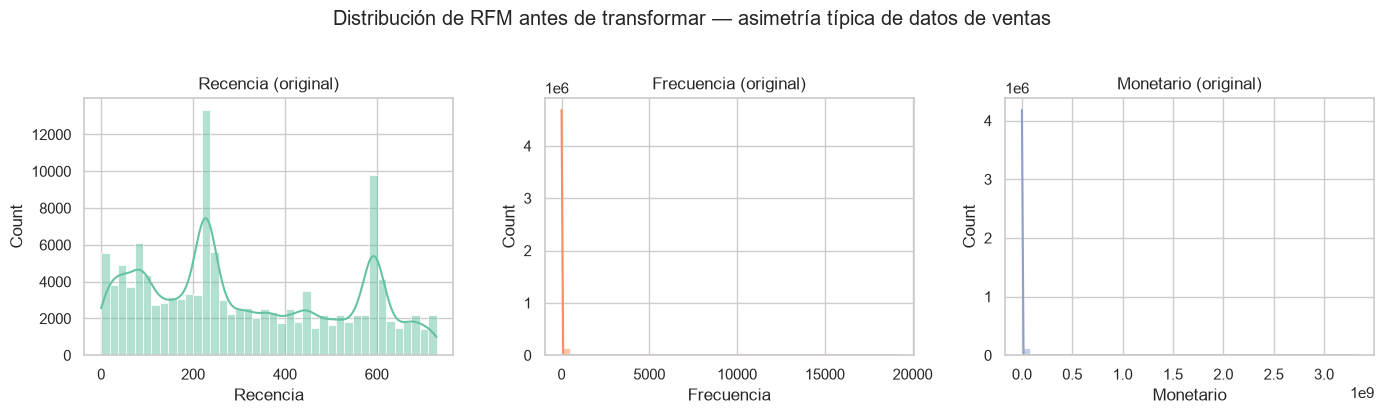

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, color in zip(axes, ["Recencia", "Frecuencia", "Monetario"], sns.color_palette("Set2", 3)):
    sns.histplot(rfm[col], bins=40, kde=True, ax=ax, color=color)
    ax.set_title(f"{col} (original)")
fig.suptitle("Distribución de RFM antes de transformar — asimetría típica de datos de ventas", y=1.03)
fig.tight_layout()
fig.savefig("grafico_1_distribucion_rfm_original.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Preparación de features (log + estandarización)

Aplicamos `log1p` para reducir la asimetría y luego `StandardScaler` para poner las tres variables en la misma escala. K-Means agrupa por distancia euclidiana, así que sin este paso el Monetario (con valores mucho más grandes) dominaría por completo la distancia y la Recencia/Frecuencia casi no pesarían en el resultado.

**Gráfico 2** muestra el efecto: las distribuciones quedan mucho más simétricas.

In [9]:
features = rfm[["Recencia", "Frecuencia", "Monetario"]].copy()

# log1p evita problemas con valores en 0 (p.ej. Recencia=0)
features_log = np.log1p(features)

scaler = StandardScaler()
X = scaler.fit_transform(features_log)

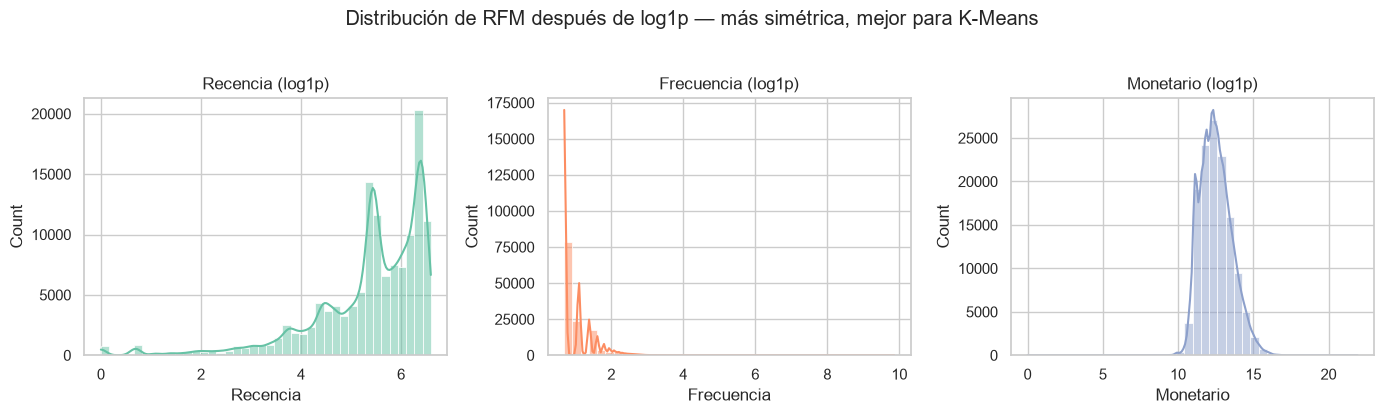

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, color in zip(axes, ["Recencia", "Frecuencia", "Monetario"], sns.color_palette("Set2", 3)):
    sns.histplot(features_log[col], bins=40, kde=True, ax=ax, color=color)
    ax.set_title(f"{col} (log1p)")
fig.suptitle("Distribución de RFM después de log1p — más simétrica, mejor para K-Means", y=1.03)
fig.tight_layout()
fig.savefig("grafico_2_distribucion_rfm_log.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Elección de K (método del codo + silhouette)

**Gráfico 3.** Probamos k entre 2 y 10 y medimos dos cosas: la inercia (qué tan compactos quedan los clusters — buscamos el "codo" donde deja de bajar mucho) y el silhouette score (qué tan bien separados están — más alto es mejor). El k marcado con la línea punteada es el que mejor equilibrio logra según silhouette.

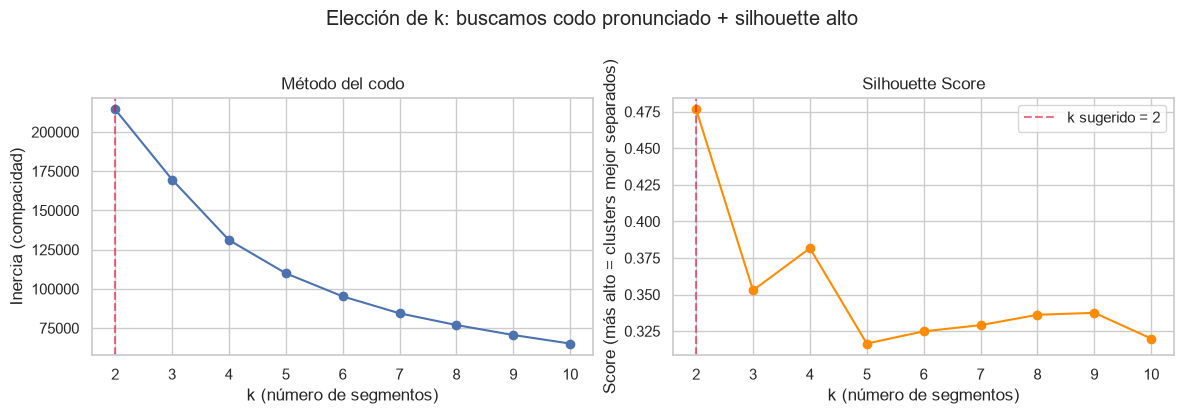

k=2: silhouette=0.477  <-- sugerido
k=3: silhouette=0.353
k=4: silhouette=0.382
k=5: silhouette=0.317
k=6: silhouette=0.325
k=7: silhouette=0.329
k=8: silhouette=0.336
k=9: silhouette=0.338
k=10: silhouette=0.320


In [11]:
inertias = []
silhouettes = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels))

k_sugerido = list(k_range)[int(np.argmax(silhouettes))]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].axvline(k_sugerido, color="crimson", linestyle="--", alpha=0.6)
axes[0].set_title("Método del codo")
axes[0].set_xlabel("k (número de segmentos)")
axes[0].set_ylabel("Inercia (compacidad)")

axes[1].plot(list(k_range), silhouettes, marker="o", color="darkorange")
axes[1].axvline(k_sugerido, color="crimson", linestyle="--", alpha=0.6, label=f"k sugerido = {k_sugerido}")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k (número de segmentos)")
axes[1].set_ylabel("Score (más alto = clusters mejor separados)")
axes[1].legend()

fig.suptitle("Elección de k: buscamos codo pronunciado + silhouette alto", y=1.03)
fig.tight_layout()
fig.savefig("grafico_3_eleccion_k.png", dpi=150, bbox_inches="tight")
plt.show()

for k, s in zip(k_range, silhouettes):
    marca = "  <-- sugerido" if k == k_sugerido else ""
    print(f"k={k}: silhouette={s:.3f}{marca}")

## 6. Modelo final

Por defecto se usa el `k` sugerido arriba. Si el negocio prefiere otra cantidad de segmentos (por ejemplo, para calzar con un número de campañas ya definido), simplemente sobrescribe `N_CLUSTERS` con un entero fijo.

In [ ]:
N_CLUSTERS = 4  # <-- sobrescribe aquí con un entero fijo si el negocio prefiere otro k

kmeans_final = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
rfm["Cluster"] = kmeans_final.fit_predict(X)

print(f"k elegido: {N_CLUSTERS}")
print(f"Silhouette final: {silhouette_score(X, rfm['Cluster']):.3f}")

k elegido: 4
Silhouette final: 0.382


## 7. Perfil de clusters y etiquetas de negocio

In [13]:
perfil = (
    rfm.groupby("Cluster")
    .agg(
        Clientes=("ID_Cliente_Unico", "count"),
        Recencia_prom=("Recencia", "mean"),
        Frecuencia_prom=("Frecuencia", "mean"),
        Monetario_prom=("Monetario", "mean"),
    )
    .sort_values("Monetario_prom", ascending=False)
)
perfil

,Clientes,Recencia_prom,Frecuencia_prom,Monetario_prom
Cluster,,,,
2,14040,91.129274,8.117094,2.327131e+06
1,34944,303.531078,2.387792,6.380083e+05
3,15390,52.943210,1.411956,2.829944e+05
0,66768,429.499790,1.059265,1.626697e+05


In [14]:
# Etiquetas legibles según ranking de valor (Monetario + Frecuencia), de mayor a menor.
# Revisa el perfil de arriba: si el orden de negocio no calza con esta lista, ajústala.
orden_valor = perfil.sort_values(["Monetario_prom", "Frecuencia_prom"], ascending=False).index.tolist()

etiquetas_por_rango = ["Campeones", "Clientes Leales", "Potencial", "En Riesgo", "Perdidos", "Ocasionales"]
mapa_etiqueta = {
    cluster_id: etiquetas_por_rango[i] if i < len(etiquetas_por_rango) else f"Segmento {i + 1}"
    for i, cluster_id in enumerate(orden_valor)
}

rfm["Segmento_KMeans"] = rfm["Cluster"].map(mapa_etiqueta)

# Orden y paleta de colores fijos para que todos los gráficos siguientes sean consistentes
seg_order = [mapa_etiqueta[c] for c in orden_valor]
paleta = dict(zip(seg_order, sns.color_palette("Set2", len(seg_order))))

rfm["Segmento_KMeans"].value_counts().reindex(seg_order)

Segmento_KMeans
Campeones          14040
Clientes Leales    34944
Potencial          15390
En Riesgo          66768
Name: count, dtype: int64

## 8. Visualizando los clusters (PCA 2D)

**Gráfico 4.** Reducimos las 3 dimensiones (R, F, M) a 2 con PCA solo para poder graficar. Sirve para mostrarle al equipo, de un vistazo, qué tan bien separados quedan los grupos — el título indica qué porcentaje de la información original conserva el gráfico.

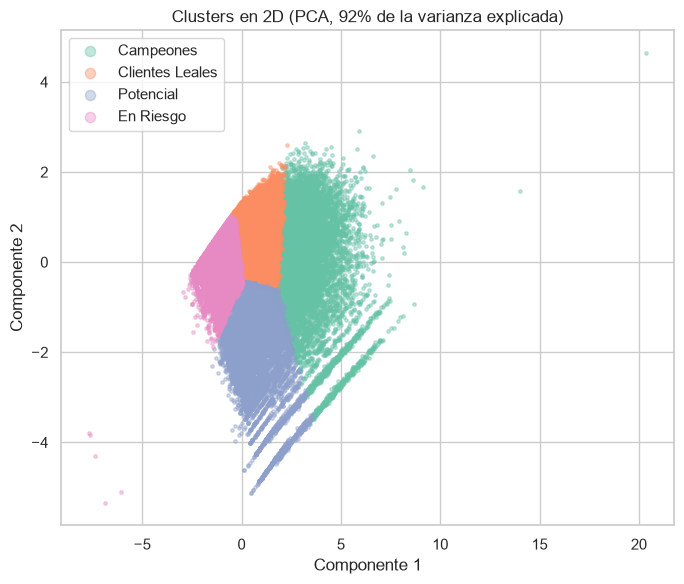

In [15]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
rfm["PCA1"], rfm["PCA2"] = coords[:, 0], coords[:, 1]

fig, ax = plt.subplots(figsize=(7, 6))
for seg in seg_order:
    mask = rfm["Segmento_KMeans"] == seg
    ax.scatter(rfm.loc[mask, "PCA1"], rfm.loc[mask, "PCA2"], s=6, alpha=0.4, color=paleta[seg], label=seg)
ax.set_title(f"Clusters en 2D (PCA, {pca.explained_variance_ratio_.sum():.0%} de la varianza explicada)")
ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
ax.legend(markerscale=3)
fig.tight_layout()
fig.savefig("grafico_4_clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Cómo se comporta cada segmento

**Gráfico 5.** Boxplots de Recencia, Frecuencia y Monetario por segmento — la forma más directa de explicarle al equipo qué distingue a cada grupo (ej. "Campeones compran seguido y gastan más", "En Riesgo lleva mucho tiempo sin comprar").

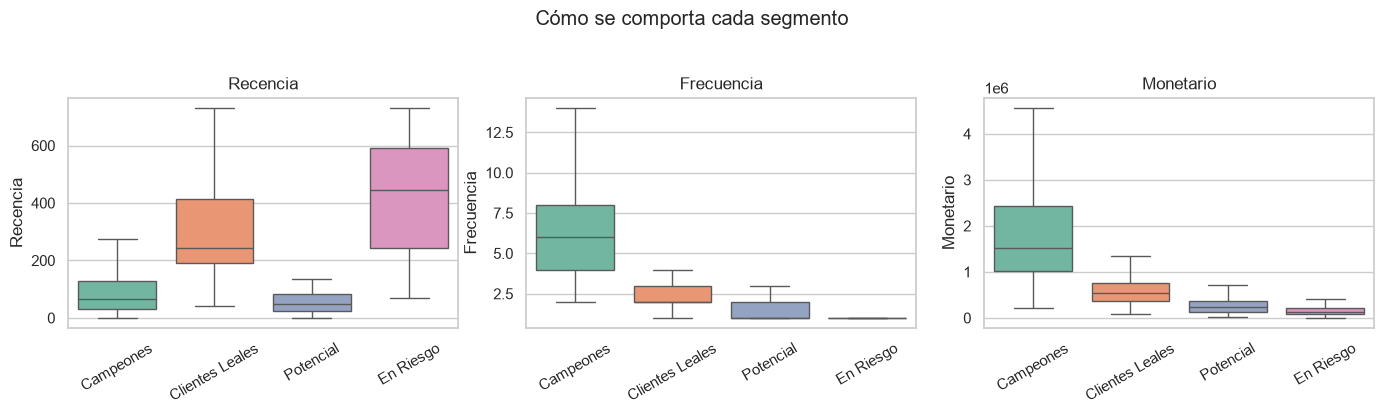

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Recencia", "Frecuencia", "Monetario"]):
    sns.boxplot(
        data=rfm, x="Segmento_KMeans", y=col, hue="Segmento_KMeans",
        order=seg_order, hue_order=seg_order, palette=paleta, legend=False,
        ax=ax, showfliers=False,
    )
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Cómo se comporta cada segmento", y=1.03)
fig.tight_layout()
fig.savefig("grafico_5_comportamiento_segmentos.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Peso de cada segmento: clientes vs. ingresos

**Gráfico 6.** El argumento más fuerte para el negocio: comparar el % de clientes que tiene cada segmento contra el % de ingresos que aporta. Cuando un segmento pequeño concentra una parte grande de los ingresos, es la evidencia de por qué vale la pena tratarlo distinto (retención prioritaria, por ejemplo).

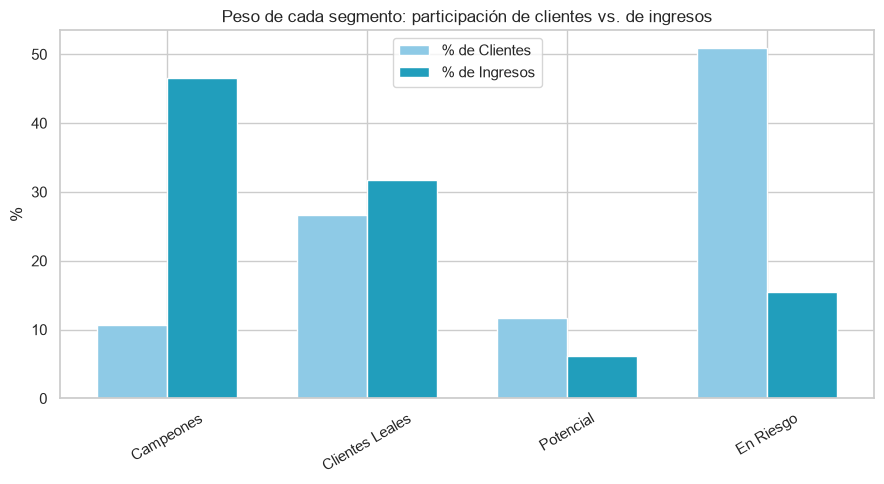

,Clientes,Ingresos,%Clientes,%Ingresos
Segmento_KMeans,,,,
Campeones,14040,3.267291e+10,10.7,46.6
Clientes Leales,34944,2.229456e+10,26.6,31.8
Potencial,15390,4.355283e+09,11.7,6.2
En Riesgo,66768,1.086113e+10,50.9,15.5


In [17]:
resumen_negocio = (
    rfm.groupby("Segmento_KMeans")
    .agg(Clientes=("ID_Cliente_Unico", "count"), Ingresos=("Monetario", "sum"))
    .reindex(seg_order)
)
resumen_negocio["%Clientes"] = resumen_negocio["Clientes"] / resumen_negocio["Clientes"].sum() * 100
resumen_negocio["%Ingresos"] = resumen_negocio["Ingresos"] / resumen_negocio["Ingresos"].sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(seg_order))
width = 0.35
ax.bar(x - width / 2, resumen_negocio["%Clientes"], width, label="% de Clientes", color="#8ecae6")
ax.bar(x + width / 2, resumen_negocio["%Ingresos"], width, label="% de Ingresos", color="#219ebc")
ax.set_xticks(x)
ax.set_xticklabels(seg_order, rotation=30)
ax.set_ylabel("%")
ax.set_title("Peso de cada segmento: participación de clientes vs. de ingresos")
ax.legend()
fig.tight_layout()
fig.savefig("grafico_6_clientes_vs_ingresos.png", dpi=150, bbox_inches="tight")
plt.show()

resumen_negocio.round(1)

## 11. Perfil comparativo (radar)

**Gráfico 7.** Un vistazo único con los 3 segmentos superpuestos: cada eje está normalizado entre 0 y 1 (más alto = mejor en esa dimensión), así que la forma de cada polígono resume de inmediato el "carácter" de cada segmento.

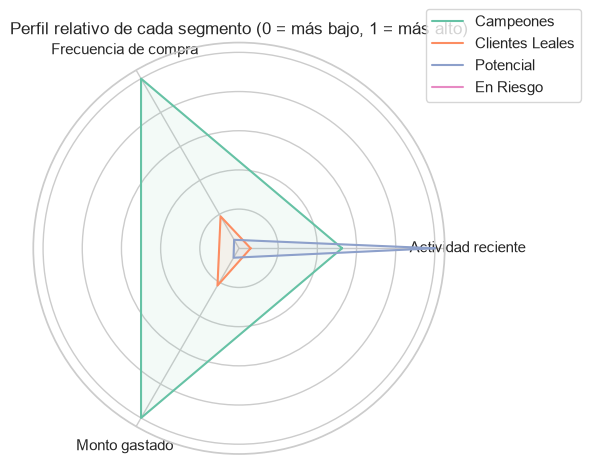

In [18]:
perfil_norm = rfm.groupby("Segmento_KMeans")[["Recencia", "Frecuencia", "Monetario"]].mean().reindex(seg_order)
perfil_norm["Actividad_Reciente"] = 1 / (perfil_norm["Recencia"] + 1)  # menor recencia = mejor -> se invierte
radar_df = perfil_norm[["Actividad_Reciente", "Frecuencia", "Monetario"]]
radar_df = (radar_df - radar_df.min()) / (radar_df.max() - radar_df.min())

categorias = ["Actividad reciente", "Frecuencia de compra", "Monto gastado"]
N = len(categorias)
angulos = [i / N * 2 * pi for i in range(N)]
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
for seg in seg_order:
    valores = radar_df.loc[seg].tolist()
    valores += valores[:1]
    ax.plot(angulos, valores, label=seg, color=paleta[seg])
    ax.fill(angulos, valores, alpha=0.08, color=paleta[seg])

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(categorias)
ax.set_yticklabels([])
ax.set_title("Perfil relativo de cada segmento (0 = más bajo, 1 = más alto)")
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
fig.tight_layout()
fig.savefig("grafico_7_perfil_radar.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Resumen para el equipo

Texto generado automáticamente con los números clave de esta corrida — útil como punto de partida para la presentación.

In [19]:
segmento_principal = resumen_negocio["Ingresos"].idxmax()
fila = resumen_negocio.loc[segmento_principal]

print("RESUMEN PARA EL EQUIPO")
print("=" * 60)
print(f"- Se probaron k entre 2 y 10; el mejor balance compacidad/separación")
print(f"  se da en k={N_CLUSTERS} (silhouette={silhouette_score(X, rfm['Cluster']):.3f}).")
print(f"- A diferencia de la segmentación por reglas fijas (Bronce/Plata/Oro/Diamante),")
print(f"  K-Means agrupa a los clientes por su comportamiento real de compra (R, F, M),")
print(f"  sin umbrales de negocio predefinidos.")
print(f"- El segmento '{segmento_principal}' representa el {fila['%Clientes']:.1f}% de los clientes")
print(f"  pero aporta el {fila['%Ingresos']:.1f}% de los ingresos del periodo analizado")
print(f"  -> prioridad de retención/fidelización.")
print(f"- Gráficos guardados en esta carpeta: grafico_1 a grafico_7 (.png), listos para la presentación.")

RESUMEN PARA EL EQUIPO
- Se probaron k entre 2 y 10; el mejor balance compacidad/separación
  se da en k=4 (silhouette=0.382).
- A diferencia de la segmentación por reglas fijas (Bronce/Plata/Oro/Diamante),
  K-Means agrupa a los clientes por su comportamiento real de compra (R, F, M),
  sin umbrales de negocio predefinidos.
- El segmento 'Campeones' representa el 10.7% de los clientes
  pero aporta el 46.6% de los ingresos del periodo analizado
  -> prioridad de retención/fidelización.
- Gráficos guardados en esta carpeta: grafico_1 a grafico_7 (.png), listos para la presentación.


## 13. Resultado final por Cliente

In [24]:
df_master = pd.read_sql("""
SELECT ID_Cliente_Unico
FROM Ventas_Comerssia.dbo.MASTER_ID
""", engine)

resultado_final = df_master.merge(
    rfm[["ID_Cliente_Unico", "Recencia", "Frecuencia", "Monetario", "Cluster", "Segmento_KMeans"]],
    on="ID_Cliente_Unico",
    how="inner",
)

print(f"Total filas (clientes): {len(resultado_final):,}")
resultado_final.head(20)

Total filas (clientes): 143,324


,ID_Cliente_Unico,Recencia,Frecuencia,Monetario,Cluster,Segmento_KMeans
0,493873,41,1,212511.87,3,Potencial
1,493874,41,1,129831.93,3,Potencial
2,493875,41,1,300840.33,3,Potencial
3,493876,42,1,170160.75,3,Potencial
4,493877,41,1,193605.12,3,Potencial
5,493879,41,1,151254.00,3,Potencial
6,493880,42,1,215966.39,3,Potencial
7,493882,42,1,214285.71,3,Potencial
8,493883,40,1,74789.92,3,Potencial
9,493885,41,1,187815.12,3,Potencial


## 14. Exportar resultados

In [25]:
with pd.ExcelWriter("segmentacion_kmeans.xlsx") as writer:
    resultado_final.to_excel(writer, sheet_name="Clientes", index=False)
    perfil.round(1).to_excel(writer, sheet_name="Perfil_Clusters")
    resumen_negocio.round(1).to_excel(writer, sheet_name="Resumen_Negocio")

print("Exportado: segmentacion_kmeans.xlsx (hojas: Clientes, Perfil_Clusters, Resumen_Negocio)")
print("Gráficos exportados como PNG en esta misma carpeta (grafico_1 ... grafico_7)")

# Descomentar para escribir en SQL Server (crea/reemplaza la tabla Segmentacion_KMeans)
# resultado_final.to_sql("Segmentacion_KMeans", engine, if_exists="replace", index=False)

Exportado: segmentacion_kmeans.xlsx (hojas: Clientes, Perfil_Clusters, Resumen_Negocio)
Gráficos exportados como PNG en esta misma carpeta (grafico_1 ... grafico_7)
